In [1]:
import os
import cv2
import numpy as np
from matplotlib import pyplot as plt

### Aplicação
"Escanear" capas de livro fotografadas tortas, deixando como se fossem vistas de frente.

In [2]:
pasta_livros = "images/capas/"
pasta_resultados = "resultados/"
os.makedirs(pasta_resultados, exist_ok=True)

### Os 4 cantos
Marcamos os cantos das capas na mão, sempre na ordem: superior esquerdo, superior direito, inferior direito, inferior esquerdo.

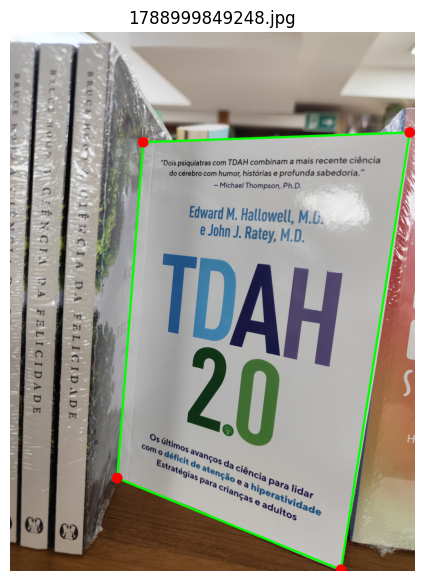

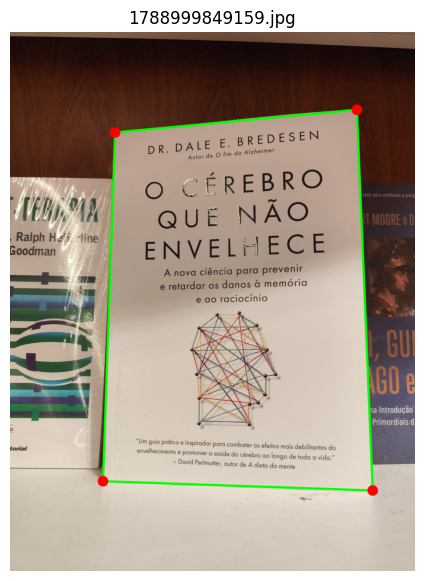

In [3]:
cantos_livros = {
    "1788999849248.jpg": [[1006, 834], [3020, 760], [2500, 4070], [810, 3376]],   # TDAH 2.0
    "1788999849159.jpg": [[794, 760], [2620, 588], [2740, 3470], [702, 3400]],    # O cérebro que não envelhece
}

def mostra(imagens, titulos):
    plt.figure(figsize=(6 * len(imagens), 7))
    for i, (img, titulo) in enumerate(zip(imagens, titulos)):
        plt.subplot(1, len(imagens), i + 1)
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.title(titulo)
        plt.axis("off")
    plt.show()

for nome, pts in cantos_livros.items():
    image = cv2.imread(os.path.join(pasta_livros, nome))
    marcada = image.copy()
    cv2.polylines(marcada, [np.array(pts)], True, (0, 255, 0), 15)
    for p in pts:
        cv2.circle(marcada, tuple(p), 40, (0, 0, 255), -1)
    mostra([marcada], [nome])

### Tamanho da imagem final
Pesquisamos as medidas dos livros na internet: *TDAH 2.0* tem 14 x 21 cm e *O cérebro que não envelhece* tem 16 x 23 cm. Usamos 100 pixels por cm.

In [4]:
tamanho_cm = {
    "1788999849248.jpg": (14, 21),   # TDAH 2.0
    "1788999849159.jpg": (16, 23),   # O cérebro que não envelhece
}

### Transformação perspectiva
`getPerspectiveTransform` calcula a matriz H a partir dos 4 pontos e `warpPerspective` aplica ela na imagem.

1788999849248.jpg tamanho final: 1400 x 2100
H =
 [[ 1.0988000e+00  8.4700000e-02 -1.1760751e+03]
 [ 3.2100000e-02  8.7340000e-01 -7.6073380e+02]
 [ 2.0000000e-04 -0.0000000e+00  1.0000000e+00]]


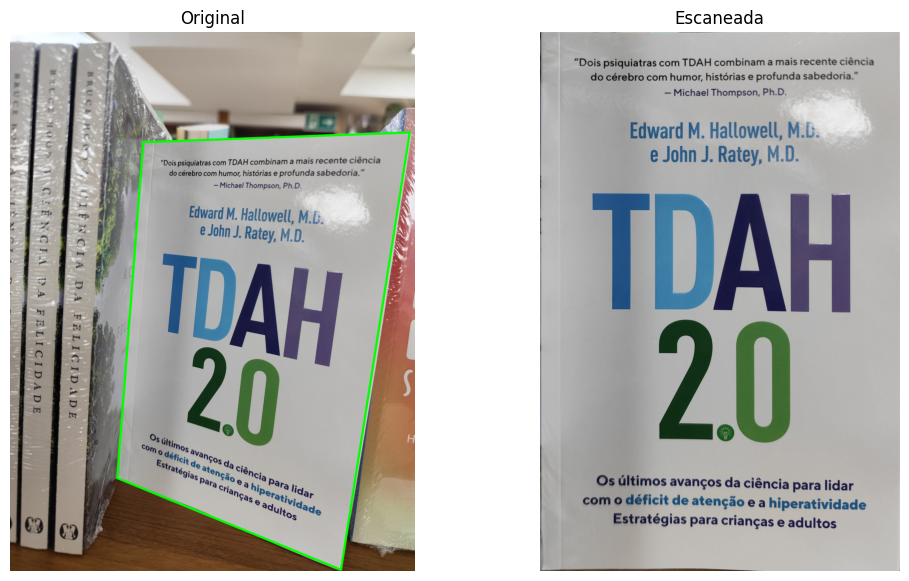

1788999849159.jpg tamanho final: 1600 x 2300
H =
 [[ 1.034100e+00  3.600000e-02 -8.484834e+02]
 [ 9.880000e-02  1.048600e+00 -8.753277e+02]
 [ 1.000000e-04  0.000000e+00  1.000000e+00]]


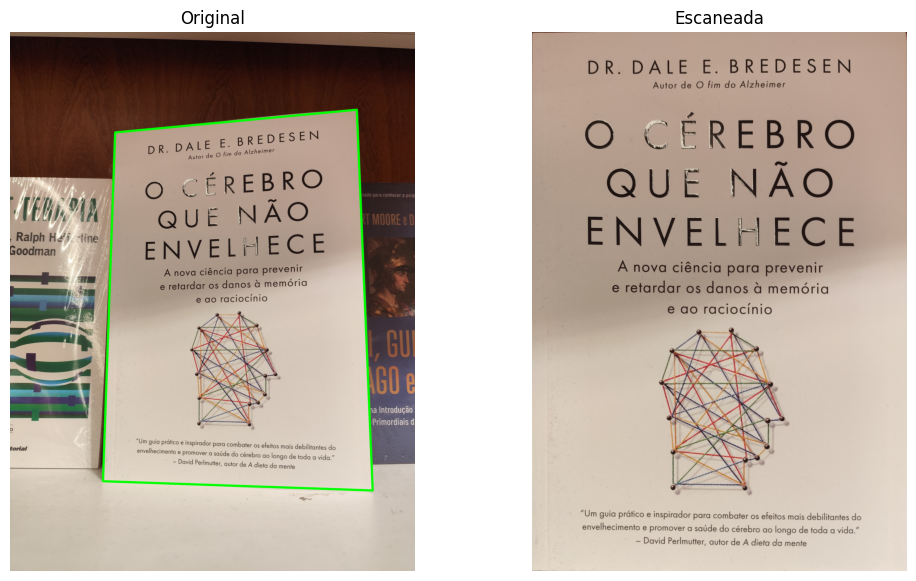

In [5]:
def escanear(image, pts, largura, altura):
    origem = np.array(pts, dtype=np.float32)
    destino = np.array([[0, 0], [largura - 1, 0], [largura - 1, altura - 1], [0, altura - 1]], dtype=np.float32)
    H = cv2.getPerspectiveTransform(origem, destino)
    return cv2.warpPerspective(image, H, (largura, altura)), H

for nome, pts in cantos_livros.items():
    image = cv2.imread(os.path.join(pasta_livros, nome))
    largura, altura = tamanho_cm[nome]
    escaneada, H = escanear(image, pts, largura * 100, altura * 100)
    print(nome, "tamanho final:", escaneada.shape[1], "x", escaneada.shape[0])
    print("H =\n", H.round(4))
    cv2.imwrite(os.path.join(pasta_resultados, "escaneado_" + nome), escaneada)

    marcada = image.copy()
    cv2.polylines(marcada, [np.array(pts)], True, (0, 255, 0), 15)
    mostra([marcada, escaneada], ["Original", "Escaneada"])

### E sem saber a medida?
Dá pra usar o maior comprimento entre as bordas opostas, mas isso não garante a proporção certa, porque a borda mais longe da câmera parece menor:

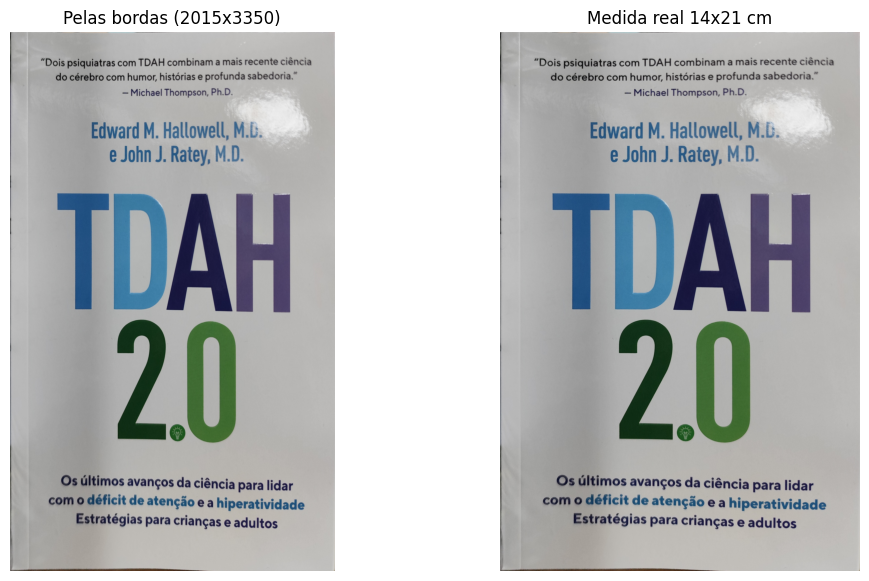

In [6]:
def tamanho_pelas_bordas(pts):
    tl, tr, br, bl = np.array(pts, dtype=np.float32)
    largura = max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl))
    altura = max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr))
    return int(largura), int(altura)

nome = "1788999849248.jpg"
image = cv2.imread(os.path.join(pasta_livros, nome))
largura_bordas, altura_bordas = tamanho_pelas_bordas(cantos_livros[nome])
pelas_bordas, _ = escanear(image, cantos_livros[nome], largura_bordas, altura_bordas)
real, _ = escanear(image, cantos_livros[nome], 1400, 2100)
mostra([pelas_bordas, real], ["Pelas bordas (%dx%d)" % (largura_bordas, altura_bordas), "Medida real 14x21 cm"])

## Livro aberto
Aqui a página é curva perto da lombada, então uma homografia só não resolve.

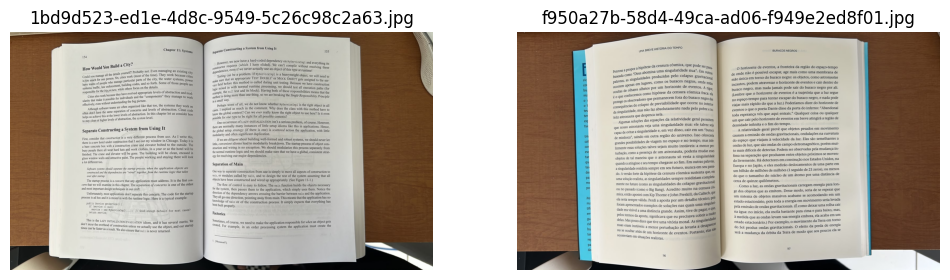

In [7]:
pasta_abertos = "images/livros_abertos/"
abertos = sorted(os.listdir(pasta_abertos))
imagens_abertas = [cv2.imread(os.path.join(pasta_abertos, nome)) for nome in abertos]
mostra(imagens_abertas, abertos)

### Achando as páginas
A página é clara e pouco saturada, e a mesa é marrom. Em HSV pegamos os pixels com S < 60 e V > 150, fechamos os buracos das letras e ficamos com o maior pedaço.

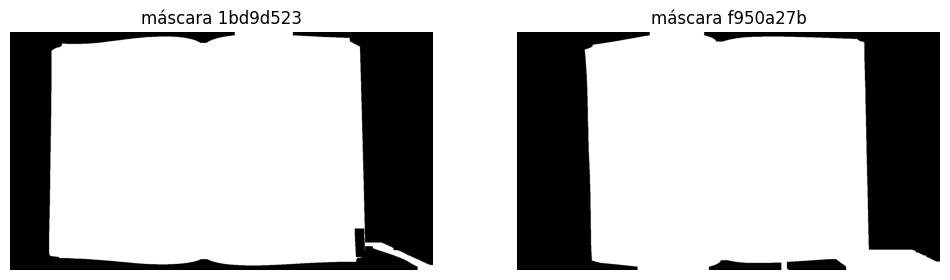

In [8]:
def mascara_paginas(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    mascara = ((hsv[:, :, 1] < 60) & (hsv[:, :, 2] > 150)).astype(np.uint8) * 255
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, np.ones((25, 25), np.uint8))
    n, rotulos, stats, _ = cv2.connectedComponentsWithStats(mascara)
    maior = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return (rotulos == maior).astype(np.uint8) * 255

mascaras = [mascara_paginas(img) for img in imagens_abertas]
mostra([cv2.cvtColor(m, cv2.COLOR_GRAY2BGR) for m in mascaras], ["máscara " + n[:8] for n in abertos])

### Bordas e lombada
Em cada coluna, o primeiro pixel da máscara é a borda de cima e o último é a de baixo. A lombada é onde a borda de cima mais afunda, no terço do meio.

página de x=157 até x=1309, lombada em x=719
página de x=280 até x=1315, lombada em x=754


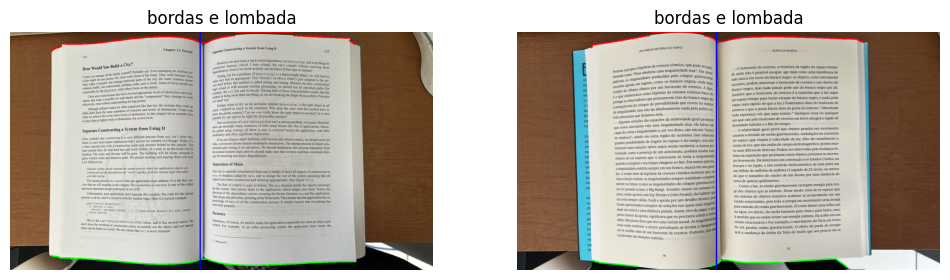

In [9]:
def bordas(mascara):
    topo = np.array([np.argmax(mascara[:, x] > 0) for x in range(mascara.shape[1])], float)
    base = np.array([mascara.shape[0] - 1 - np.argmax(mascara[::-1, x] > 0) for x in range(mascara.shape[1])], float)
    altura_coluna = (mascara > 0).sum(axis=0)
    colunas = np.where(altura_coluna > 0.8 * np.percentile(altura_coluna, 90))[0]
    x0, x1 = colunas[0], colunas[-1]
    terco = (x1 - x0) // 3
    lombada = x0 + terco + int(np.argmax(topo[x0 + terco:x1 - terco]))
    return x0, x1, lombada, topo, base

dados_abertos = []
desenhos = []
for img, m in zip(imagens_abertas, mascaras):
    x0, x1, lombada, topo, base = bordas(m)
    dados_abertos.append((x0, x1, lombada, topo, base))
    print("página de x=%d até x=%d, lombada em x=%d" % (x0, x1, lombada))
    desenho = img.copy()
    for x in range(x0, x1, 4):
        cv2.circle(desenho, (x, int(topo[x])), 3, (0, 0, 255), -1)
        cv2.circle(desenho, (x, int(base[x])), 3, (0, 255, 0), -1)
    cv2.line(desenho, (lombada, 0), (lombada, img.shape[0]), (255, 0, 0), 3)
    desenhos.append(desenho)
mostra(desenhos, ["bordas e lombada"] * len(desenhos))

### Retificando em faixas
Cortamos cada página em faixas verticais estreitas, que são quase planas, e fazemos uma homografia por faixa. Com 1 faixa é a transformação normal de 4 cantos.

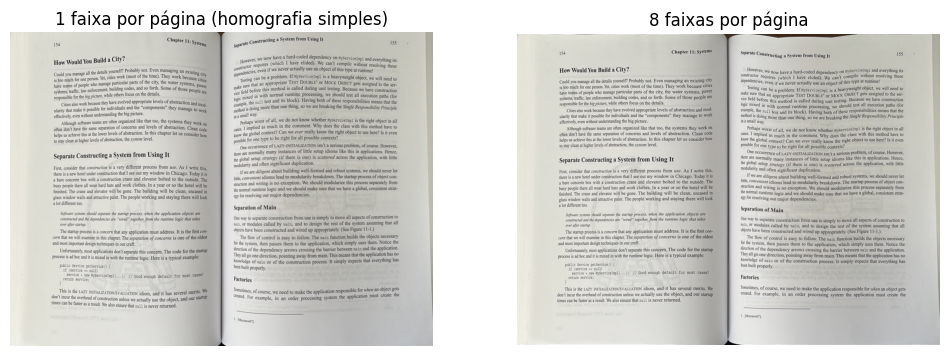

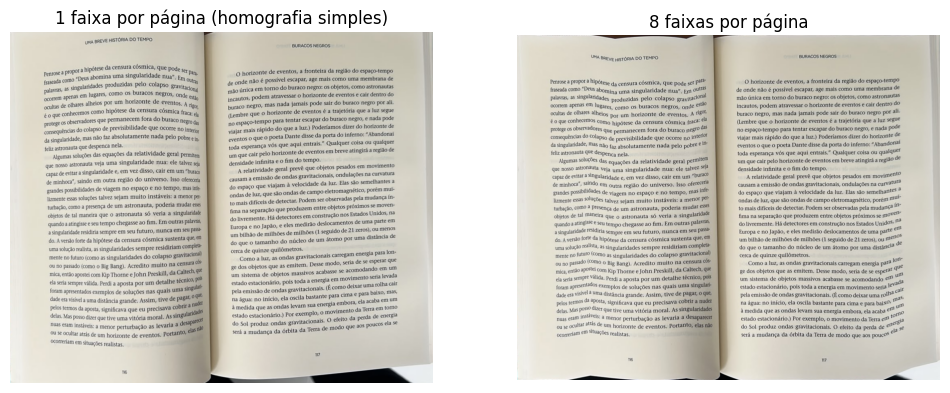

In [10]:
def retifica_faixas(image, xs, topo, base, altura):
    partes = []
    for a, b in zip(xs[:-1], xs[1:]):
        origem = np.float32([[a, topo[a]], [b, topo[b]], [b, base[b]], [a, base[a]]])
        largura = int(round((np.linalg.norm(origem[1] - origem[0]) + np.linalg.norm(origem[2] - origem[3])) / 2))
        destino = np.float32([[0, 0], [largura, 0], [largura, altura], [0, altura]])
        H = cv2.getPerspectiveTransform(origem, destino)
        partes.append(cv2.warpPerspective(image, H, (largura, altura)))
    return np.hstack(partes)

def escanear_livro_aberto(image, dados, n_faixas):
    x0, x1, lombada, topo, base = dados
    altura = int(np.median(base[x0:x1] - topo[x0:x1]))
    esquerda = retifica_faixas(image, np.linspace(x0 + 3, lombada, n_faixas + 1).astype(int), topo, base, altura)
    direita = retifica_faixas(image, np.linspace(lombada, x1 - 3, n_faixas + 1).astype(int), topo, base, altura)
    return esquerda, direita

for nome, img, dados in zip(abertos, imagens_abertas, dados_abertos):
    esq_1, dir_1 = escanear_livro_aberto(img, dados, 1)
    esq_8, dir_8 = escanear_livro_aberto(img, dados, 8)
    mostra([np.hstack([esq_1, dir_1]), np.hstack([esq_8, dir_8])], ["1 faixa por página (homografia simples)", "8 faixas por página"])
    cv2.imwrite(os.path.join(pasta_resultados, "aberto_1faixa_" + nome), np.hstack([esq_1, dir_1]))
    cv2.imwrite(os.path.join(pasta_resultados, "aberto_8faixas_" + nome), np.hstack([esq_8, dir_8]))

Com 8 faixas o texto perto da lombada fica bem mais reto, mas ainda um pouco espremido e as linhas saem meio onduladas. Achamos que é por dois motivos:
- Cada faixa usa só 4 pontos das bordas de cima e de baixo, na mesma coluna da imagem. Isso supõe que uma coluna vertical da foto é uma coluna vertical da página, o que só vale com a câmera bem em cima do livro. Como a foto é meio inclinada, nas emendas das faixas as linhas dão pequenos saltos.
- As bordas vêm da máscara, que tem ruído (sombra, a grossura das folhas aparecendo do lado). Qualquer ondinha na borda vira ondinha no texto.

Tentamos casar os pontos de cima e de baixo pelo comprimento da borda em vez da coluna, mas com as bordas ruidosas ficou pior. Pra resolver de verdade teria que usar as próprias linhas de texto como guia.

### Cara de scanner
O `adaptiveThreshold` deixa a página preto e branco e tira a sombra da lombada.

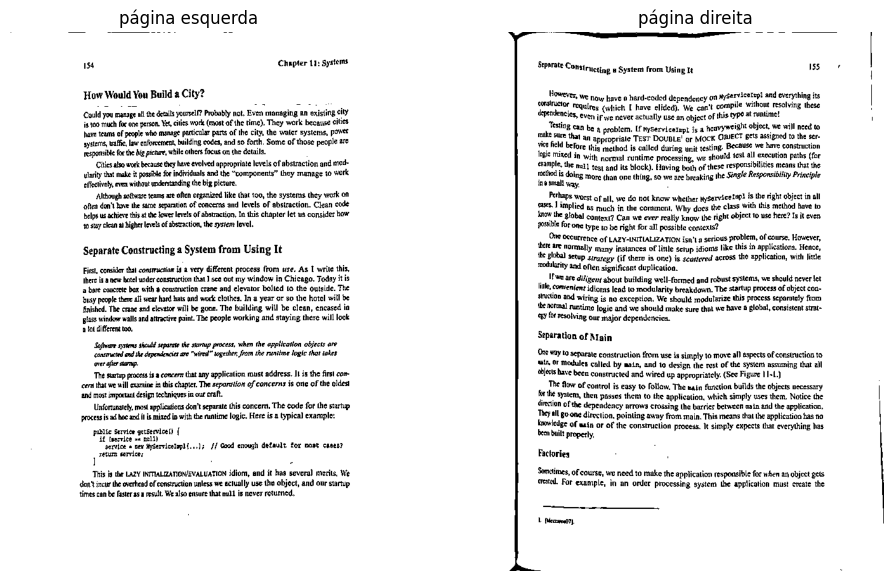

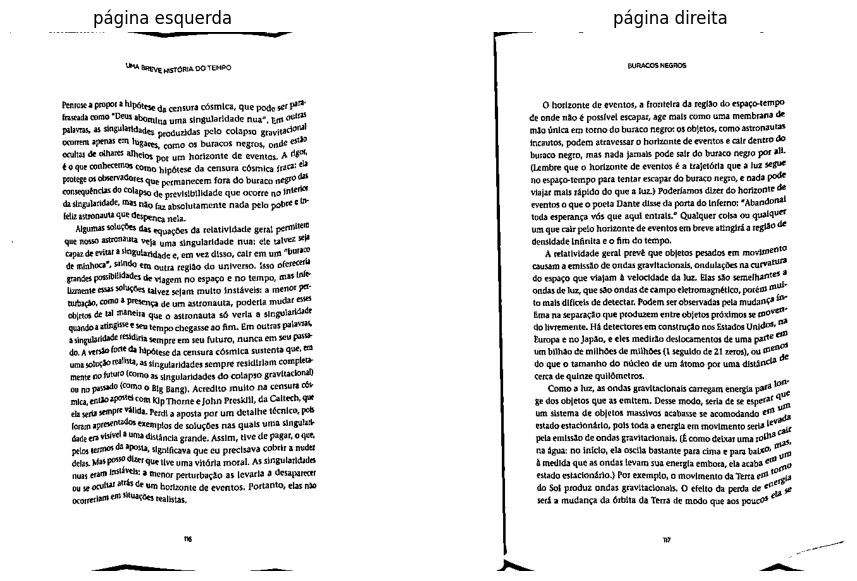

In [11]:
for nome, img, dados in zip(abertos, imagens_abertas, dados_abertos):
    esq, dir_ = escanear_livro_aberto(img, dados, 8)
    paginas = []
    for pagina in [esq, dir_]:
        cinza = cv2.cvtColor(pagina, cv2.COLOR_BGR2GRAY)
        paginas.append(cv2.adaptiveThreshold(cinza, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, 15))
    cv2.imwrite(os.path.join(pasta_resultados, "aberto_scanner_esq_" + nome), paginas[0])
    cv2.imwrite(os.path.join(pasta_resultados, "aberto_scanner_dir_" + nome), paginas[1])
    mostra([cv2.cvtColor(p, cv2.COLOR_GRAY2BGR) for p in paginas], ["página esquerda", "página direita"])